# 01 · Исследование данных и регрессия

Цель: предсказать количественную целевую переменную на Diabetes. Сравниваем константный baseline, Ridge и Lasso. Метрики: RMSE, MAE, R².

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'mlproject').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the project folder')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from mlproject.data import dataset, split
from mlproject.experiments import run


In [2]:
X,y=dataset('regression')
display(X.head())
display(X.describe().round(2))
print('Размер:',X.shape,'Пропуски:',int(X.isna().sum().sum()),'Дубликаты признаков:',int(X.duplicated().sum()))

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00
mean,48.52,1.47,26.38,94.65,189.14,115.44,49.79,4.07,4.64,91.26
std,13.11,0.50,4.42,13.83,34.61,30.41,12.93,1.29,0.52,11.50
min,19.00,1.00,18.00,62.00,97.00,41.60,22.00,2.00,3.26,58.00
25%,38.25,1.00,23.20,84.00,164.25,96.05,40.25,3.00,4.28,83.25
50%,50.00,1.00,25.70,93.00,186.00,113.00,48.00,4.00,4.62,91.00
75%,59.00,2.00,29.28,105.00,209.75,134.50,57.75,5.00,5.00,98.00
max,79.00,2.00,42.20,133.00,301.00,242.40,99.00,9.09,6.11,124.00


Размер: (442, 10) Пропуски: 0 Дубликаты признаков: 0


## EDA только на обучающей части

Корреляции используются для описания, не для отбора по test. Исходные признаки загружены с `scaled=False`; StandardScaler обучается внутри pipeline.

In [3]:
train_X,train_y=split('regression')['train']
display(train_X.corrwith(train_y).sort_values().rename('train_target_correlation').to_frame())

,train_target_correlation
s3,-0.379832
sex,-0.027541
s2,0.107255
s1,0.162307
age,0.206081
s6,0.386699
s4,0.407563
bp,0.419677
s5,0.564526
bmi,0.595427


## Выбор регуляризации

Для Ridge/Lasso проверяем alpha = 0.01, 0.1, 1, 10, 100. Выбор по минимальному validation RMSE. Состав train не меняется после выбора; test оценивается один раз для выбранной конфигурации каждого семейства.

In [4]:
results=run('01')
display(results.round(4))
display(pd.read_csv(ROOT/'reports/01_regression_tuning.csv').round(4))

,model,rmse,mae,r2,alpha,val_rmse
0,Dummy mean,72.9002,63.5314,-0.0031,NaN,NaN
1,Ridge,54.0309,42.9704,0.4490,1.0,51.1031
2,Lasso,53.3024,42.7218,0.4637,1.0,51.0602


,model,alpha,val_rmse
0,Ridge,0.01,51.1916
1,Ridge,0.10,51.1741
2,Ridge,1.00,51.1031
3,Ridge,10.00,51.1605
4,Ridge,100.00,51.7369
5,Lasso,0.01,51.1777
6,Lasso,0.10,51.0997
7,Lasso,1.00,51.0602
8,Lasso,10.00,53.1511
9,Lasso,100.00,75.6392


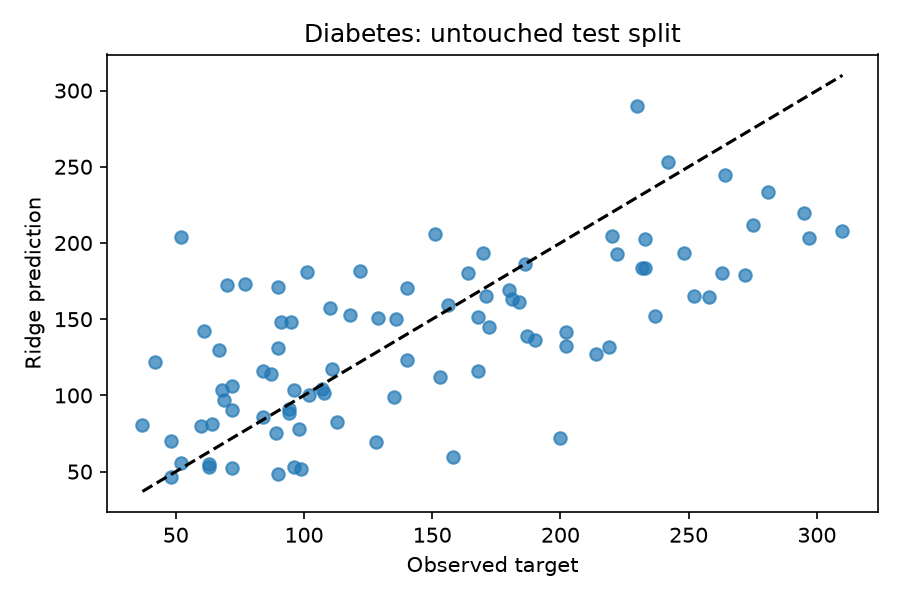

In [5]:
display(Image(filename=str(ROOT/'reports/01_regression.png')))

In [6]:
baseline=float(results.loc[results.model=='Dummy mean','rmse'].iloc[0])
selected=results.dropna(subset=['val_rmse']).sort_values('val_rmse').iloc[0]
print(f'Выбрана по validation: {selected.model}. Test RMSE={selected.rmse:.2f}, R2={selected.r2:.3f}.')
print(f'Снижение RMSE относительно baseline: {(baseline-selected.rmse)/baseline:.1%}.')

Выбрана по validation: Lasso. Test RMSE=53.30, R2=0.464.
Снижение RMSE относительно baseline: 26.9%.


## Ограничения

Небольшая выборка и один split. Ошибки на графике не доказывают причинную связь. Для устойчивого сравнения следующим шагом нужна вложенная кросс-валидация.